# Quantum Metal tutorial 4.43 — the 10 × 10 bare-paddle transmon array of the package-mode study (Quantcore PDK rebuild)

**What the chip is.** The Qiskit Metal tutorial `docs/tut/4-Analysis/4.43-Mesh-and-solve-the-10x10-processor.ipynb`;
the layout is `pm.build_design()` in `docs/tut/resources/package_modes/package_modes.py` (shared by tutorials
4.41–4.46), © Qiskit Metal contributors, Apache-2.0 (<https://github.com/qiskit-community/qiskit-metal>). The device
is the validation processor of R. Molavi *et al.*, "Extracting electromagnetic bare mode couplings in large
superconducting quantum processors", arXiv:2609.22442 (2026), Fig. 4; spec `docs/designs/metal/tut443_10x10_package.md`.
We distribute the rebuild under GPL-3.0. 100 bare transmons, each two 0.5 × 1 mm paddles side by side along x
across a 0.2 mm junction gap, on a 3 mm pitch ((i + 0.5)·3, (j + 0.5)·3) mm, on a 30 × 30 mm chip with **no ground
plane** (0.5 mm silicon in a 30 × 30 × 3 mm metal box). No routes, resonators or ports: it is a package-mode study.

**This notebook rebuilds it with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`): the
chip, the stack, the junctions, the netlist and the LOM are ours.

| | Qiskit Metal 4.43 (`package_modes.py`) | Quantcore PDK rebuild |
|---|---|---|
| chip | 30 × 30 mm, spanning 0…30 mm (Designer = Metal + (0, 0)) | the same 30 × 30 mm box with the QCT die frame |
| substrate | 0.5 mm silicon in a 3 mm metal box | sapphire 650 µm, εr 10.25 (LOM and FEM; the FEM box is the PDK's, not the 3 mm lid) |
| ground plane | none | a chip-wide etch (`metal:Rectangle`, `subtract`) stopping 0.7 mm inside the die edge, so the frame's dicing L's and alignment grids sit in ground metal (the paddles start 1.25 mm from the edge) |
| pads | none | none (nothing for the pad rule to move) |
| qubits | the resource module's own `TwoPadTransmon` (defined inside a function, not importable) | qcc's `TwoPadTransmon`, its geometric twin: `pad_thickness` 500, `pad_height` 1000, `gap` 200, no leads (`a = 0`), no pocket (`pocket_margin = 0`) |
| junctions | a lumped element (a 20 µm junction-table line, no metal; the paper's fit 3.63 nH) | a Quantcore trilayer junction drawn across each 200 µm gap, sized by the PDK rule for 4.05 GHz: L_J ≈ 5.34 nH, C_J ≈ 19 fF, R_n ≈ 36 kΩ (just below the 40–50 kΩ window: flagged) |
| cheese | none (no GDS export) | the PDK band (chip `cheese: "auto"`): with no ground plane only the 0.7 mm rim round the etch has ground to cheese |
| placement | as drawn | content centred in the die (already centred) |

**Kept exactly:** positions, paddle sizes, gap, orientation and the chip size.

**Not reproduced:** the tutorial's gmsh + scikit-fem Maxwell solve of the package mode (7.07 GHz empty box,
6.49 GHz with silicon, 6.48 GHz with paddles) and its electrostatics (≈ 174 fF across each junction). qcc's LOM has
no package modes, and its FEM export uses the PDK's stack, not the 3 mm lid (Simulate 1).

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its own cell with a
picture of the chip so far — the die with its etched-away ground plane, the 100 two-paddle transmons, and then the
whole chip (no pads, readouts, couplings or control lines: those segments say so in one sentence). Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in one cell, with its outputs) is kept as `tut443_10x10_package.v1.ipynb`; both save the same
`tut443_10x10_package.json`.

## Setup

The imports, the output folder, the source's device numbers (`N`, `PITCH`, paddle sizes, `GAP`, `L`, the paper's values) and the switches. `LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it;
with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK placement, FEM and feedback helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots
# package_modes.DEVICE (mm): n, pitch, paddle, gap, chip
N, PITCH, PAD_W, PAD_H, GAP, L = 10, 3000, 500, 1000, 200, 30000
PAPER = {"C_qubit_fF": 173.8, "f_box_pads_GHz": 6.48}  # zfit_q00 C_n; package mode with paddles

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this chip that means: the 30 mm box gets the QCT frame; there are no pads for the pad rule; every qubit gets a trilayer junction across its gap, sized by the PDK rule; the cheese band only finds ground in the rim round the chip-wide etch.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way a designer would lay it out by hand: the die, the bond pads, the readout, the qubits, the
coupling, the control lines, and then the whole chip. Each segment is one cell with one picture of the chip so far
(and, live, KLayout redraws after every cell). Only segments 1 and 4 place anything: the etch that takes the ground plane away, and the qubit array.

| segment | what is placed here |
|---|---|
| 1 | the 30 × 30 mm die with the QCT frame, and the chip-wide etch (no ground plane) |
| 2–3 | nothing: a package-mode study has no bond pads and no feedline |
| 4 | the 100 two-paddle transmons with their trilayer junctions |
| 5–7 | nothing: no readouts, no couplers (the qubits couple only through the package), no control lines |
| 8 | the whole chip: sim groups, centring, save |

## Design 1 · The die, its frame and the missing ground plane

`Designer(name, box=...)` opens an empty chip. The box is the die (µm); the PDK draws the **QCT frame** on it: L
dicing markers in the four corners (1000/0), a 3 × 3 alignment grid in each corner area (1001/0), the chip boundary
(100/0) and the device ID `name_chip` on a free edge (optional: no free edge, no ID). The source's chip spans
0…30 mm, so Designer = Metal + (0, 0).

**No ground plane.** The source has none: the paddles see the box floor through the substrate. A chip-sized
`metal:Rectangle` with `subtract: true` etches the ground away, 0.7 mm inside the die edge so the frame markers stay
in ground metal; the paddles' metal is drawn over it.

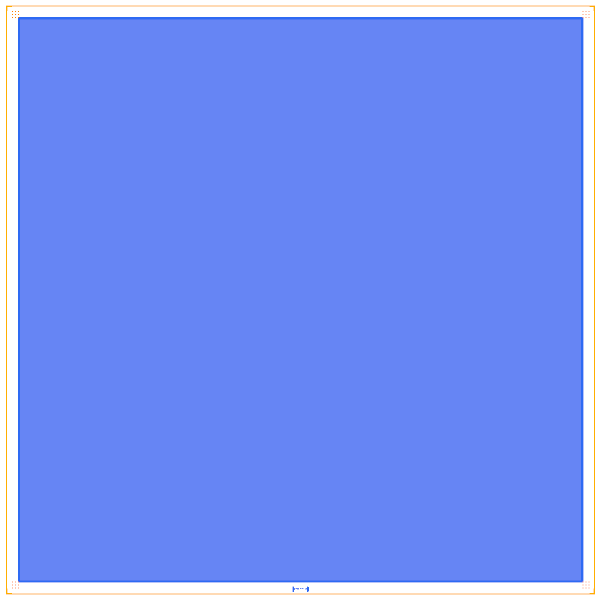

**On the chip so far:** 0 pads · 0 qubits · 1 other components · 0 routes · 0 declared couplings. **This step added** 1 component(s) `no_ground`.

WindowsPath('examples/designs/metal/tut443_10x10_package_s1_die.png')

In [5]:
d = Designer("tut443_10x10_package", box=(0, 0, L, L), chip={"name_chip": "MetalTut443"}, live=LIVE)
with d.batch():
    d.add("no_ground", "metal:Rectangle", at=(L / 2, L / 2), width=L - 1400, height=L - 1400, subtract=True)   # no ground plane (inside the PDK frame)
layout_step(d, OUT / "tut443_10x10_package_s1_die.png", size=(600, 600), width=300)

## Design 2 · Bond pads

The package-mode study has no launchpads, so the PDK pad rule (outer etch edge 100 µm from the die edge) has nothing
to place; `pads_md(d)` in Design 8 confirms there are none.

## Design 3 · Readout: the line

No feedline or readout pads either: the source reads nothing out, it solves the package's modes.

## Design 4 · Qubit placement: 100 two-paddle transmons

**The qubit.** The source's `TwoPadTransmon` lives inside a function of its resource module (not an importable
`metal:` class). Its exact geometric twin is qcc's `TwoPadTransmon` (the legacy two-pad transmon) with
`pad_thickness = 500`, `pad_height = 1000`, `gap = 200`, no leads (`a = 0`) and no pocket (`pocket_margin = 0`): two
rectangles whose metal is `base_metal_addition`. Its ports `left` / `right` (pad edges) are unused.

**The junction.** `TwoPadTransmon` takes `junction_type="Quantcore Junction"` + `junction_params`, so the PDK
trilayer junction is drawn across the 200 µm pad gap. The source's value (the paper's fit, 3.63 nH) is below what the
PDK window gives, so the junction is sized by the PDK rule for **4.05 GHz** (the bottom of the PDK band) with the
C_Σ ≈ 261 fF this design's LOM gives across the gap: `size_junction` returns the fingers, R_n, L_J and C_J. Here
R_n ≈ 36 kΩ, just below the 40–50 kΩ window: the DRC flags it (`pdk_rn`), it is not retuned. `junction=` carries the
drawn junction's L_J / C_J to the LOM and the FEM junction port. (This replaces the earlier to-do note that the
junction was only assumed in the LOM.)

The picture zooms on the corner Q_0_0 … Q_1_1.

{'Lj_nH': 5.3448, 'Cj_fF': 18.9} R_n 35.6 kΩ, fingers 0.63 × 0.6 µm; R_n 35.6 kΩ is outside the process window 40–50 kΩ (f_q 4.05 GHz with C_Σ 279.8 fF needs E_J/h 30.6 GHz)
Q_0_0 ports: ['left', 'right', 'squid_a', 'squid_b']


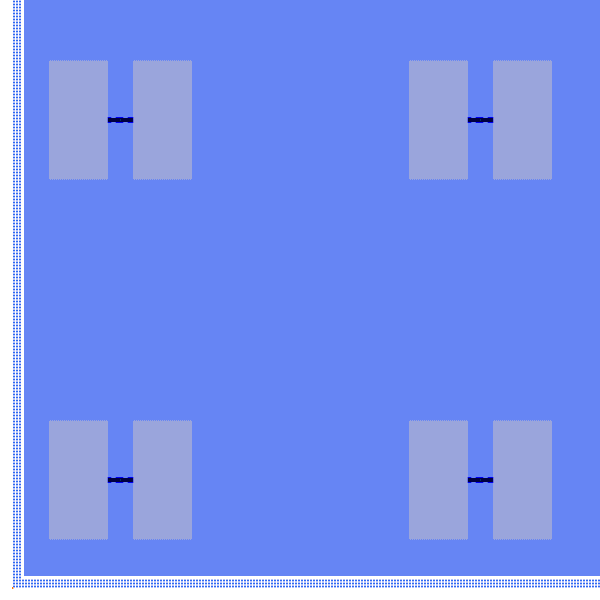

**On the chip so far:** 0 pads · 100 qubits · 1 other components · 0 routes · 0 declared couplings. **This step added** 100 component(s) `Q_0_0`, `Q_0_1`, `Q_0_2`, `Q_0_3`, `Q_0_4`, `Q_0_5`, `Q_0_6`, `Q_0_7` … (+92).

WindowsPath('examples/designs/metal/tut443_10x10_package_step_parts.png')

In [6]:
from quantcore_circuits.circuit.bridges import size_junction
# Quantcore trilayer junction drawn in each 200 µm gap (TwoPadTransmon junction_type), sized by the PDK rule
# for 4.05 GHz (bottom of the PDK band) with C_Σ ≈ 261 fF across the gap (this design's LOM before the rebuild)
SIZED = size_junction(4.05, 260.9, c_includes_junction=False)
JUNCTION = SIZED.design_junction()
print(JUNCTION, f"R_n {SIZED.rn_kohm:.1f} kΩ, fingers {SIZED.finger_width} × {SIZED.second_finger_width} µm;", *SIZED.notes)
with d.batch():
    for i in range(N):
        for j in range(N):
            d.add(f"Q_{i}_{j}", "TwoPadTransmon", at=((i + 0.5) * PITCH, (j + 0.5) * PITCH), junction=JUNCTION,
                  junction_type="Quantcore Junction", junction_params={"lj_nH": JUNCTION["Lj_nH"]},   # 5.3448 nH
                  pad_thickness=PAD_W, pad_height=PAD_H, gap=GAP, a=0, lead_length=0, pocket_margin=0)
print("Q_0_0 ports:", sorted(d["Q_0_0"].ports))
layout_step(d, OUT / "tut443_10x10_package_step_parts.png", box=(500, 500, 5500, 5500), size=(600, 600), width=300)

## Design 5–7 · Readout resonators, coupling, control lines

None. There are no routes: the 100 qubits couple only through the package modes and their (small) cross-capacitances. The LOM has no package modes, so in the circuit the qubits are uncoupled (Check 2).

## Design 8 · The whole chip: sim groups, centring, save

The **sim groups** name what a FEM job cuts out: qubit (0, 0) alone (its capacitance across the junction) and the 2 × 2
corner (the cross-capacitances), each with a 1 mm margin, for Q3D C-matrix jobs.

**Centring.** The PDK wants the chip content centred in the die. `center_in_die` measures the bounding box of everything placed
and shifts the design so its centre is the die centre. The array and the chip-wide etch are symmetric about the die
centre, so nothing moves.

**Save.** The JSON is the deliverable. `save_design` writes it and compares it with the file it replaces (the
previous run's): the segments above changed how the chip is built, not the chip, so it should say *same design*.

['Q_0_0', 'corner']


content shifted by (0.0, 0.0) µm


| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| – | no bond pads or launchers | – | – | – |

**Same design as before:** `examples/designs/metal/tut443_10x10_package.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer tut443_10x10_package: 101 instances, 0 routes, live=False> → examples\designs\metal\tut443_10x10_package.json


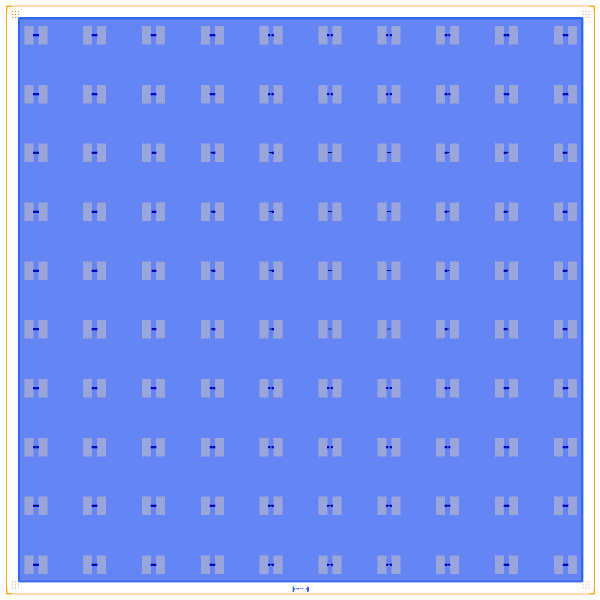

**On the chip so far:** 0 pads · 100 qubits · 1 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/tut443_10x10_package_step_routes.png')

In [7]:
# FEM: qubit (0, 0) alone (its C across the junction), and the 2 × 2 corner (cross-capacitances)
d.sim_group("Q_0_0", ["Q_0_0"], margin_um=1000, analyses=["q3d_cmatrix"])
d.sim_group("corner", ["Q_0_0", "Q_1_0", "Q_0_1", "Q_1_1"], margin_um=1000, analyses=["q3d_cmatrix"])
print(sorted(d.data["sim_groups"]))
shift = center_in_die(d)
rebuild(d)
print("content shifted by", shift, "µm")
display(Markdown(pads_md(d)))
DESIGN, same = save_design(d, OUT / "tut443_10x10_package.json")
display(Markdown(same))
print(d, "→", DESIGN)
layout_step(d, OUT / "tut443_10x10_package_step_routes.png", size=(600, 600), width=300)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip
box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the source's.

Expected here (from the v1 run): **no errors**; 400 `dangling_port` warnings (each qubit's unused `left` / `right` pad edges and
its junction refpoints `squid_a` / `squid_b`: nothing is wired on this chip); 100 `overlap` warnings (the qubits on
the chip-wide `no_ground` etch, by design); and **100 PDK design warnings `pdk_rn`** (R_n ≈ 36 kΩ, below the
40–50 kΩ window, because the junction is sized for 4.05 GHz on the large paddle capacitance).

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings.

In [ ]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit: each `TwoPadTransmon` gives two floating islands (`island1` left
paddle, `island2` right paddle), each with an analytic C to ground, C between them across the gap, and the junction.
Nothing couples the 100 qubits in the LOM: in the source they couple only through the package modes and their
(small) cross-capacitances, which the corner Q3D job gives. The first rows only, then Q_0_0's capacitances:

In [ ]:
from collections import Counter
lb = d.lom()
md_ = netlist_md(lb)
display(Markdown("\n".join(md_.splitlines()[:12]) + "\n\n…\n\n" + "\n".join(l for l in md_.splitlines() if "Q_0_0" in l and l.startswith("| `C"))))
print(Counter(b.type for b in lb.model.branches.values()))
print({k: v for k, v in lb.port_map.items() if k.startswith("Q_0_0.")})

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

Qubit (0, 0) alone (all 100 are identical and uncoupled in the LOM). QuCat gives its linear mode; QuTiP the dressed
f_q and α.

- With the PDK junction sized for 4.05 GHz, Q_0_0 lands at the bottom of the PDK band by construction.
- **The LOM overestimates C here:** qcc's `TwoPadTransmon` model puts its pads in a 50 µm pocket of a ground plane
  (≈ 408 fF per pad to ground in the v1 run), but this chip has no ground plane: the paddles see the box floor through 0.5 mm of
  silicon. The paper's impedance fit gives C_n = 173.8 fF (the tutorial's electrostatics ≈ 174 fF); with that C the
  same junction would put the qubit near 5 GHz. Request for lom (a no-ground-plane case); the Q3D job of Simulate 2
  replaces the C by net name.

In [ ]:
res = simulate_groups(d, {"Q_0_0": ["Q_0_0"]})
display(Markdown(modes_md(res["Q_0_0"]) + "\n\n" + groups_md(res)))
br = lb.model.branches
c1, c2, c12 = (br[f"C_Q_0_0_{k}"].value["estimate"] for k in ("1", "2", "12"))
c_across = c12 + c1 * c2 / (c1 + c2)
print(f"LOM C across the junction: {c_across:.0f} fF (paper's fit {PAPER['C_qubit_fF']} fF)")

## LOM 2 · The LOM in two plots

The same result as pictures: (a) the one normal mode of Q_0_0 (QuCat; the filled circle is the QuTiP dressed value),
(b) the dispersive shift panel, empty here (no resonator: the plot says so). Here (from the v1 run) Q_0_0 sits at
4.05 GHz by construction of the junction (Design 4), with a small α (≈ −72 MHz) from the large paddle capacitance.

In [ ]:
plot_lom(res, OUT / "tut443_10x10_package_lom.png", title="tut443: LOM of Q_0_0")

## LOM 3 · One geometry change, by hand

Before the FEM, a hand-made design step: copy the saved design (`design_copy`: a non-live Designer that never writes over the
JSON), change one property — here Q_0_0's paddles, `pad_height` 1000 → 800 µm — rebuild, re-run the LOM of Q_0_0
and compare. Smaller paddles have less capacitance: E_C grows, so f_q and |α| go up.

In [ ]:
d2 = design_copy(DESIGN)
d2["Q_0_0"].set(pad_height=800)                  # 1000 → 800 µm
after = simulate_groups(d2, {"Q_0_0": ["Q_0_0"]})
display(Markdown(params_delta_md(res, after)))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/metal/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (the box set by `sim_group`), puts ports where lines leave the box and writes a job folder under
`build/jobs/`. Simulation exports never get cheese, and airbridges are dropped unless asked for.

Q3D C-matrix jobs for qubit (0, 0) and for the 2 × 2 corner: they replace the LOM's paddle estimates by net
name. They use the PDK's substrate and vacuum box, not the source's 0.5 mm silicon in a 3 mm box, so they do not
reproduce the package mode; the tutorial's own solver (`package_modes.py`) does that.

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

Neither group lists an eigenmode analysis, but `export_sims` exports any analysis of an existing group, so the
eigenmode job of `Q_0_0` (Simulate 3) comes from the same design: nothing is added to it.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/metal/fem/: solved results are kept here
jobs = export_sims(DESIGN, ["Q_0_0", "corner"])
jobs_eig = export_sims(DESIGN, ["Q_0_0"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrices

The capacitance of each component group: `Q_0_0` (the two paddles as named nets: the C across the junction, the
number the LOM overestimates, LOM 1) and `corner` (the 2 × 2 corner: the small cross-capacitances between
neighbours). Each net is named after its LOM node, so the matrix goes straight into the circuit (Results 3).
`fem_stage` solves each job with `RUN_FEM`, else loads its kept results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The `Q_0_0` box in HFSS eigenmode: the junction is a lumped L_J ‖ C_J sheet; no line leaves the box, so there is no
port and the modes' Q is set by the materials only. pyEPR (run inside qcc's own AEDT, never KQC's
`run_pyepr_t1_estimate.py`) turns the junction's energy participation into Q_0_0's dressed f_q and α. The box is the
PDK's sim box round one qubit, not the source's 30 × 30 × 3 mm package, so its other modes are not the package modes
of the study.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run

Nothing to drive: the chip has no port (no pad, no line).

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: the qubit), with the LOM's Q_0_0 frequency as a dashed line. The
table below lists the modes and the pyEPR values.

In [ ]:
lom_f = {"Q_0_0": res["Q_0_0"].params.get("Q_0_0.f_q_GHz")}
plot_eigenmodes(keep_eig, OUT / "tut443_10x10_package_eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode job in the LOM's terms: Q_0_0's mode is the one its junction participates in most; f_q is pyEPR's
dressed frequency, α its self-Kerr. There is no readout to read (`epr_values` gets a placeholder readout, and only
Q_0_0's values are kept).

In [ ]:
fem_q = {}
if keep_eig["Q_0_0"]:
    fem_q = {k: v for k, v in epr_values(keep_eig["Q_0_0"], {"Q_0_0": "none"}, {"none": 0.0}).items()
             if k.startswith("Q_0_0.")}
if fem_q:
    display(Markdown("| quantity | FEM |\n|---|---|\n" + "\n".join(f"| `{k}` | {v:.5g} |" for k, v in fem_q.items())))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list Q_0_0's f_q and α from pyEPR.")

## Results 3 · FEM against the LOM

**LOM on the Q3D C-matrix:** `fill` replaces Q_0_0's paddle estimates by the `Q_0_0` job's C-matrix values (matched
by net name) and the same LOM runs again; this is where the LOM's no-ground-plane overestimate (LOM 1) shows. **FEM
directly:** Q_0_0's eigenmode values (Results 2). The left column is the LOM on the component estimates (LOM 1).

In [ ]:
from quantcore_circuits.circuit.fill import fill

est = res["Q_0_0"].params
rows = []
if keep_q3d.get("Q_0_0"):
    on_fem = simulate(fill(d.lom(select=["Q_0_0"]).model, DESIGN, keep_q3d["Q_0_0"]), max_modes=2).params
    rows += [(k, est.get(k), on_fem.get(k), "LOM on the Q3D C-matrix") for k in ("Q_0_0.f_q_GHz", "Q_0_0.alpha_MHz")]
rows += [(k, est.get(k), fem_q[k], "Q_0_0 eigenmode + pyEPR") for k in ("Q_0_0.f_q_GHz", "Q_0_0.alpha_MHz") if k in fem_q]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts Q_0_0's f_q and α of the LOM next to the LOM on "
          "the Q3D C-matrix and next to the eigenmode, with the difference in %.")

## Results 4 · Feedback: one step towards a target

The junction was sized for 4.05 GHz on the LOM's paddle capacitance, which puts its R_n at ≈ 36 kΩ, below the PDK
window (the 100 `pdk_rn` warnings of Check 1). The exercise: **move every junction into the window and bring the
qubits back to 4.05 GHz with the paddles.** First every junction goes to L_J 6.2 nH (R_n ≈ 41 kΩ, drawn with
`trilayer_junction`), which by the transmon formula lowers Q_0_0 by ≈ 0.3 GHz (from the v1 run: 4.046 GHz); then the
feedback shrinks the paddles to raise it again.

`loop.feedback` tunes qubit–readout pairs, and this chip has none, so the step is a first-order rule in the notebook:
f_q ∝ 1/√C_Σ and C_Σ grows with the paddle height, so **pad_height ← pad_height · (f_now / f_target)²** (kept
between 200 and 2000 µm), the same height for all 100 qubits, on a copy of the design (`design_copy`). Q_0_0 is
measured alone, as in LOM 1. The paddles change the capacitances, so a kept Q3D job does not hold for a revision:
without `RUN_FEM` each revision is judged on the LOM, with `RUN_FEM = True` each revision's own `Q_0_0` Q3D job is
exported and solved first (`build/jobs/rev<k>/`, kept in `fem/rev<k>/`). The table shows the junction move and one
feedback step.

In [ ]:
from quantcore_circuits.circuit.fill import fill

Q_T, F_T, TOL = "Q_0_0", 4.05, 0.020             # the exercise target: Q_0_0 (all 100 alike) at 4.05 GHz ± 20 MHz
LJ_WIN = 6.2                                     # nH: every junction moved to R_n ≈ 41 kΩ, inside the PDK window
QUBITS = [n for n, s in d.data["instances"].items() if s["cell"] == "TwoPadTransmon"]


def measure(dd, k):
    """Q_0_0's dressed f_q (GHz) of revision k (design dd, saved to build/tut443_10x10_package_target/): the LOM of
    Q_0_0 alone; with RUN_FEM on the revision's own Q_0_0 Q3D job (the paddles changed: the C-matrix is solved again)."""
    rev = dd.save(Path("build") / "tut443_10x10_package_target" / f"rev{k}.json")
    keep = None
    if RUN_FEM:
        keep = fem_stage(export_sims(rev, [Q_T], root=f"build/jobs/rev{k}"), RUN_FEM, KEEP / f"rev{k}",
                         force=RESOLVE, aedt=AEDT_MODE)[Q_T]
    return simulate(fill(dd.lom(select=[Q_T]).model, rev, keep), max_modes=2).params.get(f"{Q_T}.f_q_GHz"), keep


def pad_step(dd, f_now):
    """The feedback rule on dd: f_q ∝ 1/√C_Σ, C_Σ ∝ paddle height to first order, so h ← h · (f_now / F_T)², the same
    height for every qubit (200–2000 µm). Returns (height before, after)."""
    h = dd.data["instances"][Q_T]["params"]["pad_height"]
    h_new = round(min(max(h * (f_now / F_T) ** 2, 200.0), 2000.0), 1)
    for n in QUBITS:
        dd[n].set(pad_height=h_new)
    return h, h_new


def junction_to_window(dd):
    """Every qubit's junction drawn for L_J = LJ_WIN (fingers and C_J from trilayer_junction)."""
    jp, jj = trilayer_junction("TwoPadTransmon", lj_nH=LJ_WIN)
    for n in QUBITS:
        dd[n].set(junction=jj, **jp)
    return jj


d_t = design_copy(DESIGN, "_target")             # the revisions are made on this copy; the design file stays
jj = junction_to_window(d_t)
f0, _ = measure(d_t, 0)
h0, h1 = pad_step(d_t, f0)
f1, _ = measure(d_t, 1)
display(Markdown(before_after_md(
    {"L_J (nH)": JUNCTION["Lj_nH"], "pad_height (µm)": h0, "Q_0_0 f_q (GHz)": res["Q_0_0"].params.get("Q_0_0.f_q_GHz")},
    {"L_J (nH)": jj["Lj_nH"], "pad_height (µm)": h1, "Q_0_0 f_q (GHz)": f1})))
print(f"junction moved: f_q {f0:.4f} GHz before the paddle step; target {F_T} ± {TOL} GHz; one step leaves "
      f"{1e3 * (f1 - F_T):+.1f} MHz")

## Results 5 · Iterate to the target

The feedback step, repeated on a fresh copy (junctions moved first): measure → on target (± 20 MHz)? → else the rule
again, until on target or `MAX_ITER` steps. The rule is first order (the paddle capacitance is not proportional to
its height, and f_q = √(8 E_J E_C) − E_C), so the steps close the gap gradually. The last revision is DRC-checked:
with the junctions in the window its `pdk_rn` warnings should be gone. The table shows each iteration (on: FEM when
the revision's Q3D job was solved, else LOM), the plot the residual in tolerances (on target below 1).

In [ ]:
from quantcore_circuits.assembly.drc import check

d_t = design_copy(DESIGN, "_target")             # start again from the design
junction_to_window(d_t)
history = []
f, keep = measure(d_t, 0)
for k in range(MAX_ITER + 1):
    r = None if f is None else (f - F_T) / TOL
    history.append({"iteration": k, "design": Path(f"rev{k}.json"), "fem": keep is not None,
                    "objective": None if r is None else abs(r), "values": {f"{Q_T}.f_q_GHz": f},
                    "targets": {f"{Q_T}.f_q_GHz": (F_T, TOL)}, "on_target": r is not None and abs(r) <= 1,
                    "knobs": {}, "notes": ["rev0: every junction at L_J 6.2 nH"] if k == 0 else []})
    if history[-1]["on_target"] or r is None or k == MAX_ITER:
        break
    history[-1]["knobs"] = {"pad_height (all 100)": pad_step(d_t, f)}
    f, keep = measure(d_t, k + 1)
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "tut443_10x10_package_iterate.png")
rev = Path("build") / "tut443_10x10_package_target" / f"rev{history[-1]['iteration']}.json"
print("last design:", rev, "·", drc_md(check(str(rev))).splitlines()[0], "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

The design JSON saved in Design 8 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it.
The fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer,
100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese.** Tutorial 4.43 never exports a GDS, so the original has no cheese: the PDK band applies
(`cheese: "auto"`, the default). With no ground plane the band only finds ground in the 0.7 mm rim between the
chip-wide etch and the frame (it is never drawn over etched, empty ground); the build draws it into KQC's
`ground_grid` layer and `export_fab` keeps it (`cheese source: build`).

Command-line equivalents:
- `qcc build examples/designs/metal/<id>.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/<id>.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/<id>.json -g <group> -a q3d_cmatrix` (one FEM job).

In [ ]:
print("design file:", DESIGN)
CHEESE = True
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

## Fab 2 · Snapshots

The full chip and the corner Q_0_0 … Q_1_1 (compare the tutorial's two `qm.view` panels); qubit (0, 0)'s junction
gap with the trilayer junction; the **fab mask** at the west rim beside Q_0_0 (the cheese band in the ground rim,
the chip-wide etch, the left paddle); and the die frame's south-west corner (dicing L on 1000/0, alignment grid on
1001/0). Positions are read from the design.

In [ ]:
qx, qy = d.data["instances"]["Q_0_0"]["place"]["at"]
show_snapshot(d, OUT / "tut443_10x10_package.png", size=(1200, 1200))
show_snapshot(d, OUT / "tut443_10x10_package_corner.png", box=(qx - 1000, qy - 1000, qx + 4000, qy + 4000),
              size=(1000, 1000), width=480)
show_snapshot(d, OUT / "tut443_10x10_package_gap.png", box=(qx - 200, qy - 150, qx + 200, qy + 150), size=(800, 600),
              width=320)
snap_file(Path("build") / "tut443_10x10_package_fab.oas", OUT / "tut443_10x10_package_cheese.png",
          box=(qx - 1200, qy - 500, qx - 200, qy + 500), size=(1000, 1000), width=420)
show_snapshot(d, OUT / "tut443_10x10_package_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300);

## Summary

| | |
|---|---|
| matches the source | positions, paddle sizes, gap, orientation, chip size; the no-ground-plane chip (etched, 0.7 mm inside the frame) |
| PDK changes | QCT frame on the 30 mm box; sapphire stack; a trilayer junction drawn in every gap, sized by the PDK rule for 4.05 GHz; PDK cheese band (rim only); content centred (no shift needed); no pads to place |
| differs | the junction (PDK-sized 5.34 nH instead of the paper's 3.63 nH fit); the LOM paddle capacitance (a ground-plane model on a chip without one) |
| LOM (from the v1 run) | Q_0_0 4.046 GHz dressed (QuCat 4.116 GHz linear), α −72 MHz; LOM C across the junction 261 fF (paper's fit 173.8 fF); junction 0.63 × 0.6 µm, L_J 5.34 nH, C_J 18.9 fF, R_n 35.6 kΩ; iterate (`pad_height` 1000 → 800 µm): f_q +330 MHz, α −12.8 MHz |
| PDK design warnings | 100 × `pdk_rn` (R_n ≈ 36 kΩ < 40 kΩ) |
| layout | built in segments (die with the chip-wide etch, the 100 qubits, the whole chip; no pads, readouts, couplings or control lines); the saved JSON is the v1 notebook's |
| feedback | an exercise on a copy: every junction into the PDK window (L_J 6.2 nH), then a first-order paddle-height rule back to 4.05 GHz (no qubit–readout pair for `loop.feedback`); LOM, or each revision's own Q3D job with `RUN_FEM` |
| open | the LOM no-ground-plane model (lom request); package modes are not in the LOM; the FEM jobs (Q3D, Q_0_0 eigenmode) are exported, not solved (`RUN_FEM = False`) |